# EV Charging Session Clustering

Review 2: K-Means and Agglomerative Hierarchical Clustering.

### Objective
This notebook applies two unsupervised learning algorithms to the Electric Vehicle (EV) charging-session dataset:

1. **K-Means Clustering**
2. **Agglomerative Hierarchical Clustering**

The goal is to identify groups of charging sessions with similar connection times, charging durations, and energy-delivery patterns.

Both algorithms are evaluated using the Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index. The notebook also includes a K-Means elbow curve, hierarchical dendrograms, PCA visualizations for both algorithms, a t-SNE visualization, and cluster profiles based on the original feature values.

### Rubric mapping
- **B1 — Implementation:** Fit both clustering algorithms and obtain cluster labels (Cells 7 and 10).
- **B2 — Evaluation:** Calculate all three internal metrics for both algorithms, inspect the K-Means elbow curve, and generate hierarchical dendrograms (Cells 6, 9, and 11).
- **B3 — Visualization:** Generate PCA plots for both algorithms and a t-SNE plot for K-Means (Cells 12–14).

### Features
The clustering features are `connectionTime_decimal`, `chargingDuration`, and `kWhDelivered`. Identifier or index columns are excluded from model fitting. `dayIndicator` is not used because this analysis focuses on connection time, charging duration, and delivered energy.

### Runtime and reproducibility
The notebook uses a reproducible sample of up to **100,000 charging records** for model fitting and evaluation, depending on the number of usable records in the CSV. The dendrograms use up to 500 rows and t-SNE uses up to 1,000 rows for visualization. Silhouette Score is estimated on a shared sample of up to 5,000 rows to manage computational cost; the other two internal metrics use all clustered observations. Results describe the selected sample and may differ from results obtained using the full dataset.

## Import required libraries and configure the runtime

This cell imports the libraries used for data handling, preprocessing, clustering, evaluation, and visualization. Pandas and NumPy support data processing, Matplotlib and Seaborn support plots, Scikit-learn provides preprocessing and machine-learning methods, and SciPy is used to construct hierarchical dendrograms.

A fixed random seed is used for reproducible sampling and randomized visualization. The environment settings limit CPU thread usage and may help avoid certain Windows or numerical-library thread warnings. If the relevant libraries have already been imported, restart the kernel and run this cell first.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"

import warnings
warnings.filterwarnings("default")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.neighbors import kneighbors_graph
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## Load the EV charging dataset
This cell reads the EV charging dataset from a CSV file and checks that it has loaded correctly.

In [3]:
CSV_PATH = r"D:\5th Sem\ML\SYNTHETIC_EV_DATA.csv"  # Replace with your actual CSV filename or full path

df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
display(df.head())


Dataset shape: (1965239, 4)

Column names:
['connectionTime_decimal', 'chargingDuration', 'kWhDelivered', 'dayIndicator']

Data types:
connectionTime_decimal    float64
chargingDuration          float64
kWhDelivered              float64
dayIndicator                int64
dtype: object


,connectionTime_decimal,chargingDuration,kWhDelivered,dayIndicator
0,15.332910,2.301191,11.469551,1
1,16.811495,4.941774,3.611695,1
2,21.151696,3.567173,14.455706,1
3,14.988554,3.089371,5.985330,1
4,15.078276,0.145047,1.274458,1


## Audit the dataset

This cell examines the dataset's dimensions, data types, missing values, duplicate rows, and descriptive statistics before clustering.

This audit helps identify data-quality issues that could affect preprocessing or clustering. Duplicate rows can influence cluster composition, and unusual values may affect distance-based methods. Potential outliers are not automatically removed because they may represent genuine EV charging sessions.

In [4]:
features = [
    "connectionTime_decimal",
    "chargingDuration",
    "kWhDelivered"
]

missing_features = [col for col in features if col not in df.columns]
if missing_features:
    raise ValueError(
        f"Required columns missing: {missing_features}. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Missing values by column:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing Count"))

print("Duplicate rows:", df.duplicated().sum())
print("\nDescriptive statistics for clustering features:")
display(df[features].describe().T)

Missing values by column:


,Missing Count
connectionTime_decimal,0
chargingDuration,0
kWhDelivered,0
dayIndicator,0


Duplicate rows: 0

Descriptive statistics for clustering features:


,count,mean,std,min,25%,50%,75%,max
connectionTime_decimal,1965239.0,14.486311,6.427672,0.000007,14.247792,16.168053,18.041363,24.000000
chargingDuration,1965239.0,3.800781,3.387723,0.000014,1.443232,2.547029,5.436214,39.411059
kWhDelivered,1965239.0,9.437424,5.700660,0.000370,4.868768,9.174554,13.566734,62.537694


## Clean and select the clustering features

This cell converts the selected EV charging features to numeric values and removes rows where all selected features are missing or contain infinite values. Rows with individual missing feature values are retained for median imputation during preprocessing.

The analysis uses `connectionTime_decimal`, `chargingDuration`, and `kWhDelivered`. Identifier columns and `dayIndicator` are excluded so that clustering is based on the selected charging-session measurements rather than row identity or an additional indicator.

In [5]:
df_clean = df.copy()

for col in features:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Replace infinite values with missing values so they can be imputed
df_clean[features] = df_clean[features].replace([np.inf, -np.inf], np.nan)

# Remove rows with no usable values among the selected features
df_clean = df_clean.dropna(subset=features, how="all").copy()

print("Rows before cleaning:", len(df))
print("Rows retained for clustering:", len(df_clean))
print("\nMissing values remaining in selected features:")
display(df_clean[features].isnull().sum().to_frame("Missing Count"))

Rows before cleaning: 1965239
Rows retained for clustering: 1965239

Missing values remaining in selected features:


,Missing Count
connectionTime_decimal,0
chargingDuration,0
kWhDelivered,0


## Exploratory data analysis (EDA)

This cell visualizes the distributions of the selected charging features and their pairwise correlations before clustering.

Histograms help reveal skewed distributions and long tails, while the correlation heatmap summarizes linear relationships between connection time, charging duration, and energy delivered. These plots support understanding of the data; they do not determine cluster labels or establish causal relationships.

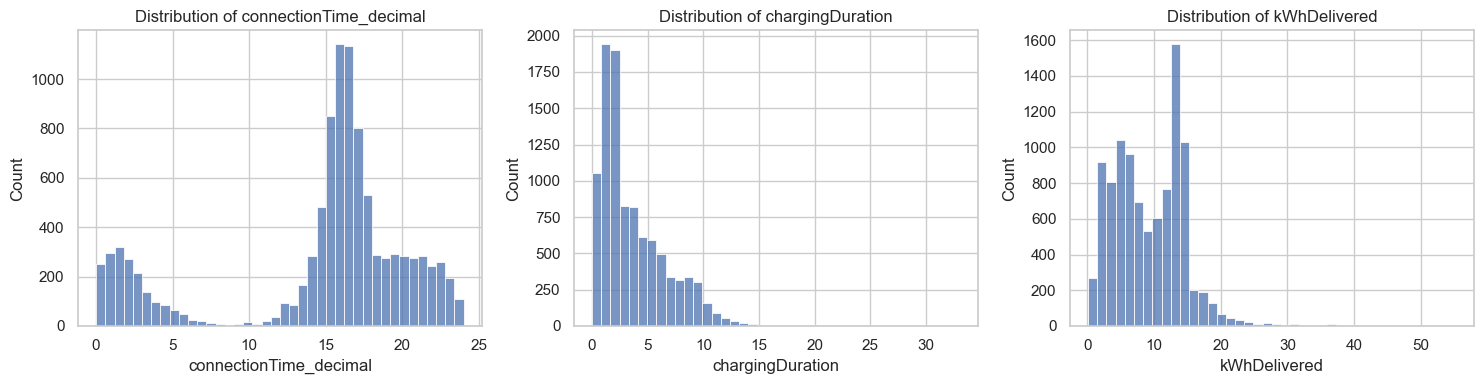

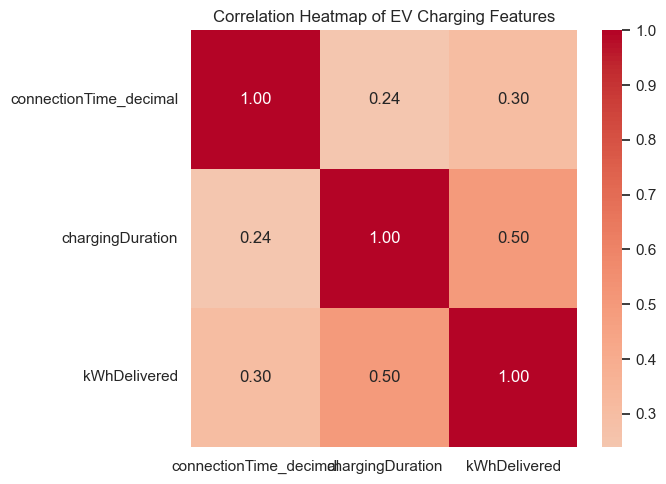

In [6]:
eda_data = df_clean[features].copy()
eda_data = eda_data.fillna(eda_data.median(numeric_only=True))
eda_data = eda_data.sample(n=min(10000, len(eda_data)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features):
    sns.histplot(eda_data[col], bins=40, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(
    eda_data[features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of EV Charging Features")
plt.tight_layout()
plt.show()

## Preprocess the data and inspect the K-Means elbow curve

This cell selects a reproducible sample of up to **100,000 charging records**, imputes missing values using the median, applies the Yeo–Johnson power transformation to reduce skewness, and standardizes the selected features. It then plots K-Means inertia for a range of cluster counts.

The transformation can reduce the influence of skewed feature distributions, while standardization places the features on comparable scales for distance-based clustering. Inertia generally decreases as the number of clusters increases; the elbow curve helps identify a candidate cluster count where additional clusters provide diminishing improvement.

The resulting standardized feature matrix is used by the later clustering and visualization cells.

Rows used for clustering: 100000
Features used: ['connectionTime_decimal', 'chargingDuration', 'kWhDelivered']
Missing values after preprocessing: 0


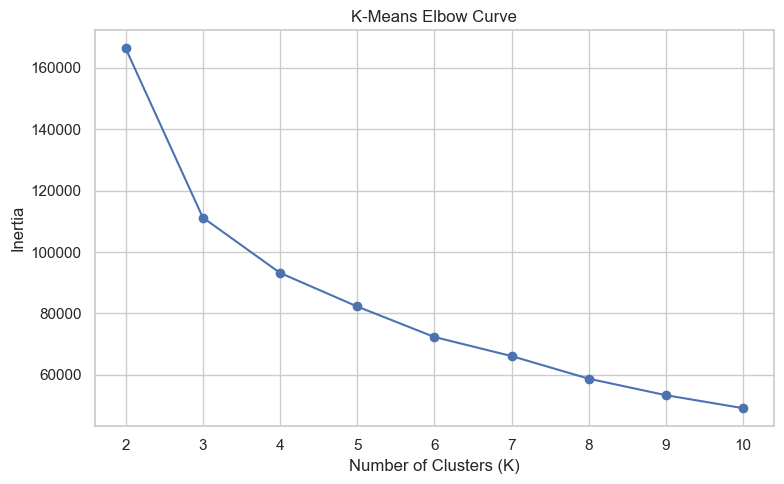

In [7]:
SAMPLE_SIZE = 100000
sample = df_clean.sample(n=min(SAMPLE_SIZE, len(df_clean)), random_state=RANDOM_STATE).copy()
X_original_sample = sample[features].copy()

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("scaler", StandardScaler())
])

X_scaled = preprocessor.fit_transform(X_original_sample)

print("Rows used for clustering:", X_scaled.shape[0])
print("Features used:", features)
print("Missing values after preprocessing:", int(np.isnan(X_scaled).sum()))

k_values = range(2, min(10, len(X_scaled) - 1) + 1)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=5, max_iter=100)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Curve")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

## B1: Fit K-Means and obtain cluster labels

This cell fits K-Means to the preprocessed sample and assigns a cluster label to each sampled charging session.

Inspect the elbow curve from Cell 6 before choosing `BEST_K`. The value of 3 in the code is an initial setting, not a guaranteed optimum. The same number of clusters is used for hierarchical clustering so that the two algorithms can be compared on a consistent basis.

In [8]:
BEST_K = 3  # Change after inspecting the elbow curve

if BEST_K >= len(X_scaled):
    raise ValueError("BEST_K must be smaller than the number of sampled rows.")

kmeans_model = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=5,
    max_iter=100
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)
sample["KMeans_Cluster"] = kmeans_labels

print("K-Means fitted successfully.")
print("\nK-Means cluster sizes:")
display(sample["KMeans_Cluster"].value_counts().sort_index().to_frame("Row Count"))

K-Means fitted successfully.

K-Means cluster sizes:


,Row Count
KMeans_Cluster,
0,35099
1,46195
2,18706


## Compare hierarchical linkage methods

This cell compares single, complete, and average linkage using a reproducible visualization subset of up to 500 charging records. The dendrograms show the order and distances at which observations or groups are merged.

- **Single linkage:** uses the minimum distance between points in two clusters.
- **Complete linkage:** uses the maximum distance between points in two clusters.
- **Average linkage:** uses the average pairwise distance between points in two clusters.

The subset is limited to keep the dendrograms computationally manageable and readable. These linkage comparisons are for visualization; the main Agglomerative model is fitted separately in the later cell.

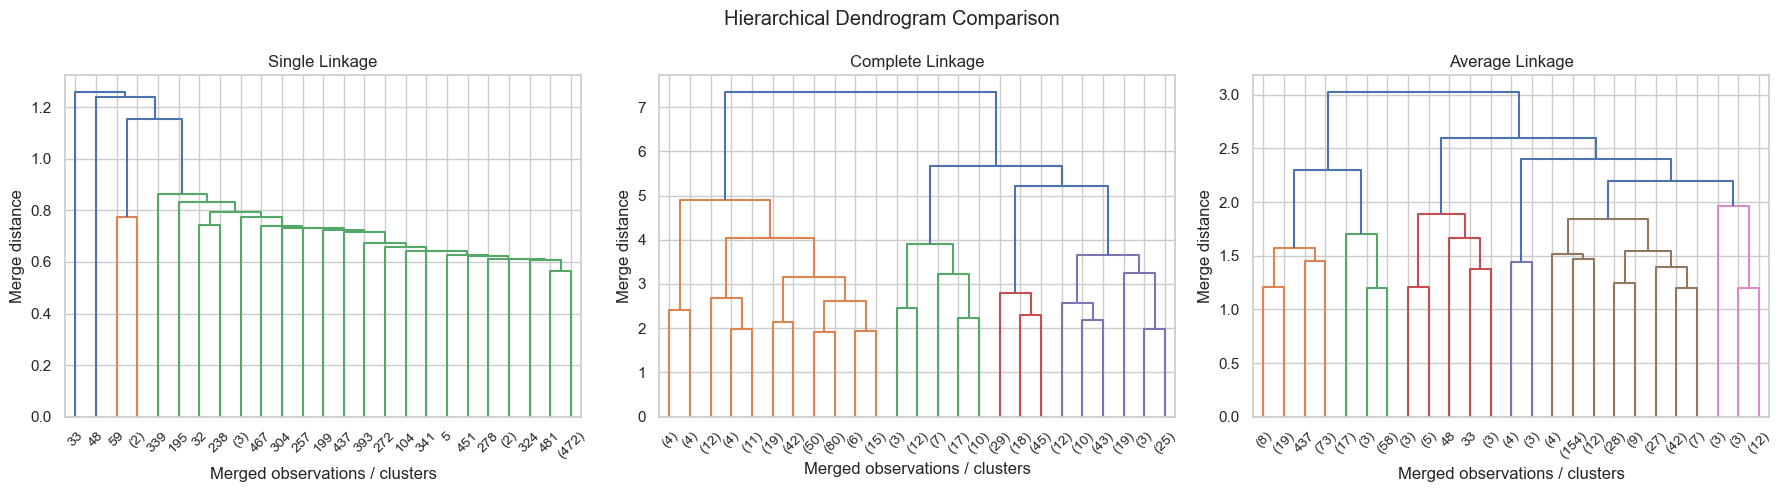

In [9]:
DENDROGRAM_SIZE = min(500, len(X_scaled))
rng = np.random.default_rng(RANDOM_STATE)
dendrogram_indices = np.sort(
    rng.choice(len(X_scaled), size=DENDROGRAM_SIZE, replace=False)
)
X_dendrogram = X_scaled[dendrogram_indices]

linkage_methods = ["single", "complete", "average"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, method in zip(axes, linkage_methods):
    Z = linkage(X_dendrogram, method=method, metric="euclidean")
    dendrogram(Z, truncate_mode="lastp", p=25, ax=ax)
    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Merged observations / clusters")
    ax.set_ylabel("Merge distance")

plt.suptitle("Hierarchical Dendrogram Comparison")
plt.tight_layout()
plt.show()

## B2: Hierarchical dendrogram using Ward linkage

This cell generates a Ward-linkage dendrogram from a visualization subset of up to 500 charging records. Ward linkage merges groups to minimize the increase in within-cluster variance at each step.

Larger vertical gaps between merges may suggest candidate cut points for forming clusters. The tree is truncated for readability and represents only the dendrogram subset, not all 100,000 potential modeling observations. The main Agglomerative clustering model is fitted separately using the larger modeling sample and a sparse nearest-neighbor connectivity graph.

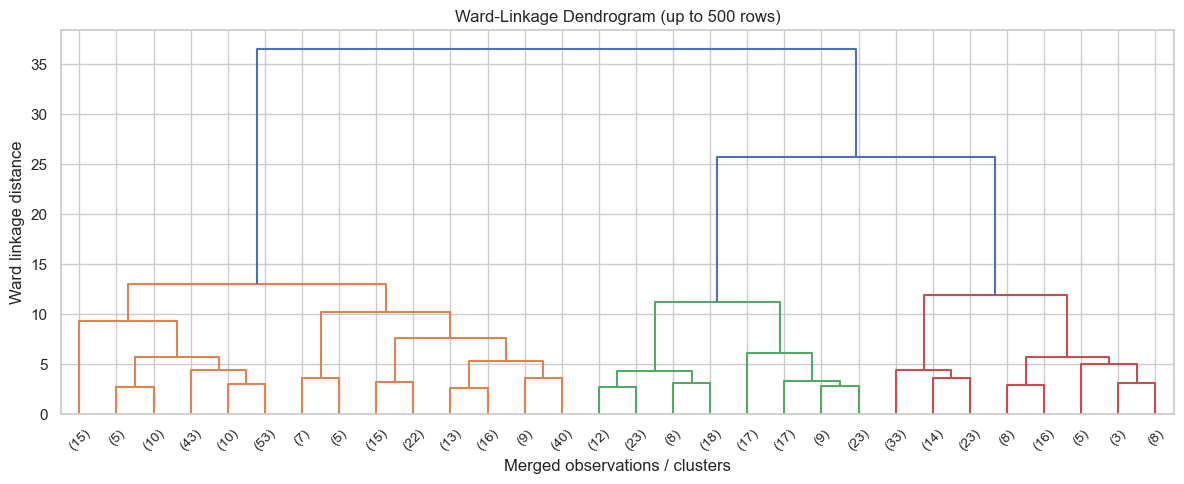

In [10]:
Z_ward = linkage(X_dendrogram, method="ward", metric="euclidean")

plt.figure(figsize=(12, 5))
dendrogram(
    Z_ward,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)
plt.title(f"Ward-Linkage Dendrogram (up to {DENDROGRAM_SIZE} rows)")
plt.xlabel("Merged observations / clusters")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

## B1: Fit Agglomerative Hierarchical Clustering

This cell fits the second required clustering algorithm and obtains cluster labels for the same preprocessed sample used by K-Means.

Ward linkage is used because it seeks to minimize the increase in within-cluster variance at each merge. Using the same standardized features and cluster count as K-Means supports a more direct comparison between the two methods. A sparse nearest-neighbor connectivity graph is used to make the larger experiment more computationally manageable.

In [11]:
# Fit Ward Agglomerative Clustering on the full 100,000-row sample.
# A sparse k-nearest-neighbor connectivity graph makes this substantially more
# scalable than unrestricted all-pairs hierarchical clustering.
N_NEIGHBORS = 10
connectivity = kneighbors_graph(
    X_scaled,
    n_neighbors=N_NEIGHBORS,
    mode="connectivity",
    include_self=False,
    n_jobs=-1
)

agg_model = AgglomerativeClustering(
    n_clusters=BEST_K,
    linkage="ward",
    connectivity=connectivity
)

agg_labels = agg_model.fit_predict(X_scaled)
sample["Hierarchical_Cluster"] = agg_labels

print("Agglomerative clustering fitted successfully on the full modeling sample.")
print("Rows clustered:", len(agg_labels))
print("Sparse connectivity: k-nearest neighbors =", N_NEIGHBORS)
print("Hierarchical cluster sizes:")
display(sample["Hierarchical_Cluster"].value_counts().sort_index().to_frame("Row Count"))

Agglomerative clustering fitted successfully on the full modeling sample.
Rows clustered: 100000
Sparse connectivity: k-nearest neighbors = 10
Hierarchical cluster sizes:


,Row Count
Hierarchical_Cluster,
0,49776
1,18803
2,31421


## B2: Evaluate both clustering algorithms

This cell calculates the Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index for K-Means and Agglomerative Hierarchical Clustering.

- **Silhouette Score:** values closer to 1 generally indicate better-defined clusters; values near 0 suggest overlapping clusters, and negative values may indicate assignments to inappropriate clusters.
- **Davies–Bouldin Index:** lower values generally indicate more compact, better-separated clusters.
- **Calinski–Harabasz Index:** higher values generally indicate greater separation between clusters relative to within-cluster dispersion.

These are internal evaluation metrics, not ground-truth accuracy scores. The Silhouette Score is estimated on the same reproducible subset for both algorithms to reduce computation, while the Davies–Bouldin and Calinski–Harabasz metrics are calculated using all clustered observations. Consider the metrics together rather than relying on a single value.

In [12]:
# Exact Silhouette computation on 100,000 rows is expensive (pairwise distances).
# Estimate it on the same reproducible subset for both algorithms. Davies-Bouldin
# and Calinski-Harabasz are computed using all rows and all cluster labels.
METRIC_SAMPLE_SIZE = min(5000, len(X_scaled))
rng = np.random.default_rng(RANDOM_STATE)
metric_indices = np.sort(rng.choice(len(X_scaled), size=METRIC_SAMPLE_SIZE, replace=False))


def evaluate_clustering(X_data, labels, name):
    return {
        "Algorithm": name,
        "Rows Clustered": len(labels),
        f"Silhouette Score (sample n={METRIC_SAMPLE_SIZE})": silhouette_score(
            X_data[metric_indices], labels[metric_indices]
        ),
        "Davies-Bouldin Index (all rows)": davies_bouldin_score(X_data, labels),
        "Calinski-Harabasz Index (all rows)": calinski_harabasz_score(X_data, labels)
    }

clustering_results_df = pd.DataFrame([
    evaluate_clustering(X_scaled, kmeans_labels, "K-Means"),
    evaluate_clustering(X_scaled, agg_labels, "Agglomerative Clustering (Ward + kNN connectivity)")
])

display(clustering_results_df.round(4))

,Algorithm,Rows Clustered,Silhouette Score (sample n=5000),Davies-Bouldin Index (all rows),Calinski-Harabasz Index (all rows)
0,K-Means,100000,0.4094,0.9195,84854.2409
1,Agglomerative Clustering (Ward + kNN connectiv...,100000,0.3898,0.9767,73872.0081


## B3: Visualize K-Means clusters using PCA

This cell projects the standardized charging features onto the first two principal components and colours each point according to its K-Means cluster assignment.

Each point represents a charging session, and colour indicates its assigned cluster. PCA reduces the feature space to two dimensions for visualization while retaining as much variance as possible in the selected components. PCA is used here for visualization only; K-Means is fitted using all three preprocessed features.

Variance explained by the first two PCA components: 88.53%


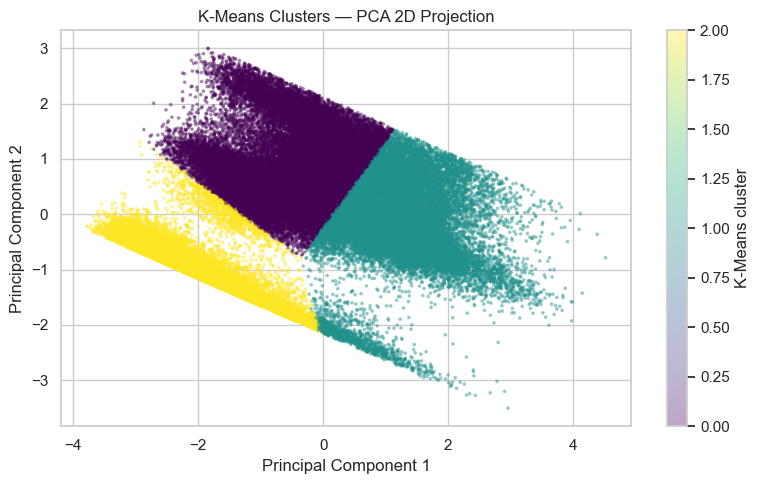

In [13]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by the first two PCA components:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=kmeans_labels, cmap="viridis",
    s=3, alpha=0.35
)
plt.title("K-Means Clusters — PCA 2D Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="K-Means cluster")
plt.tight_layout()
plt.show()

## B3: Visualize hierarchical clusters using PCA

This cell displays the PCA coordinates used in the previous visualization, with colours representing the Agglomerative Hierarchical Clustering labels.

Using the same two-dimensional PCA coordinates makes the plots from K-Means and hierarchical clustering directly comparable. The projection is intended to help inspect visible grouping and overlap; it does not replace the numerical evaluation metrics.

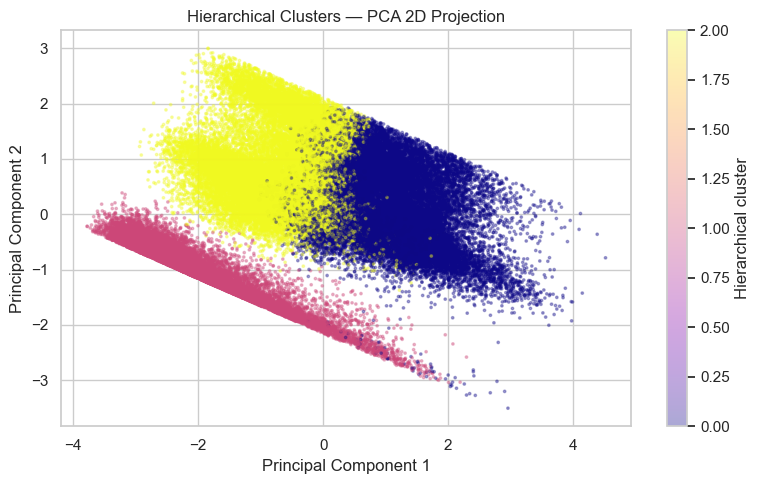

In [14]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=agg_labels, cmap="plasma",
    s=3, alpha=0.35
)
plt.title("Hierarchical Clusters — PCA 2D Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Hierarchical cluster")
plt.tight_layout()
plt.show()

## B3: Visualize K-Means clusters using t-SNE

This cell applies t-distributed Stochastic Neighbor Embedding (t-SNE) to a reproducible subset of up to 1,000 charging sessions and colours the resulting two-dimensional points by their K-Means labels.

t-SNE emphasizes local neighborhood structure and can help reveal patterns that are not obvious in a linear PCA projection. Distances between widely separated groups, apparent cluster sizes, and global geometry should be interpreted cautiously. This is a visualization of the existing K-Means assignments, not a separate clustering model.

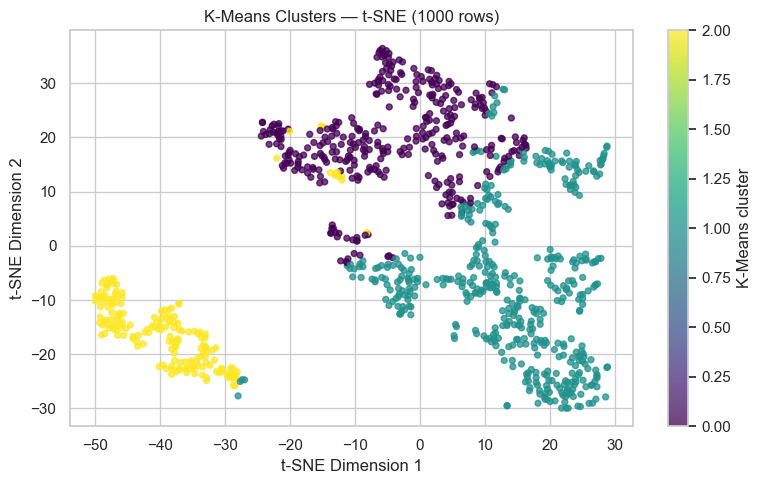

In [15]:
TSNE_SIZE = min(1000, len(X_scaled))
rng = np.random.default_rng(RANDOM_STATE)
tsne_indices = np.sort(
    rng.choice(len(X_scaled), size=TSNE_SIZE, replace=False)
)

X_tsne_input = X_scaled[tsne_indices]
tsne_labels = kmeans_labels[tsne_indices]

if TSNE_SIZE < 3:
    print("Not enough observations for t-SNE; at least 3 are needed.")
else:
    tsne = TSNE(
        n_components=2,
        perplexity=min(30, TSNE_SIZE - 1),
        learning_rate="auto",
        init="pca",
        random_state=RANDOM_STATE
    )
    X_tsne = tsne.fit_transform(X_tsne_input)

    plt.figure(figsize=(8, 5))
    scatter = plt.scatter(
        X_tsne[:, 0], X_tsne[:, 1],
        c=tsne_labels, cmap="viridis",
        s=18, alpha=0.75
    )
    plt.colorbar(scatter, label="K-Means cluster")
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.title(f"K-Means Clusters — t-SNE ({TSNE_SIZE} rows)")
    plt.tight_layout()
    plt.show()

## Interpret clusters using the original feature values

This cell summarizes the clusters using the original values of connection time, charging duration, and energy delivered, rather than the transformed and standardized values used for model fitting.

Compare the reported profiles to describe how charging sessions differ across the discovered groups. For example, a cluster with a higher average `chargingDuration` may contain longer charging sessions, while a higher average `kWhDelivered` may indicate more energy delivered per session. Use the actual profile values when drawing conclusions. Cluster numbers are arbitrary labels and do not imply an inherent ranking.

In [16]:
profiles = X_original_sample.copy()
profiles["KMeans_Cluster"] = kmeans_labels
profiles["Hierarchical_Cluster"] = agg_labels

print("K-Means cluster profiles (original units):")
display(profiles.groupby("KMeans_Cluster")[features].mean().round(3))

print("Hierarchical cluster profiles (original units):")
display(profiles.groupby("Hierarchical_Cluster")[features].mean().round(3))

K-Means cluster profiles (original units):


,connectionTime_decimal,chargingDuration,kWhDelivered
KMeans_Cluster,,,
0,17.835,1.915,6.072
1,16.723,6.262,13.922
2,2.724,1.308,4.834


Hierarchical cluster profiles (original units):


,connectionTime_decimal,chargingDuration,kWhDelivered
Hierarchical_Cluster,,,
0,17.376,5.615,13.721
1,2.259,1.787,5.429
2,17.254,2.160,5.144
